<center><h1>Gu_Dengyi_HW7</h1></center>

Name: Dengyi Gu
<br>
Github Username: DengyiGu
<br>
USC ID: 1332838543

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv("../data/anuran+calls+mfccs/Frogs_MFCCs.csv")

y = df[["Family", "Genus", "Species"]]
X = df.drop(columns=["Family", "Genus", "Species", "RecordID"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=552
)

### (b) Train a classifier for each label

#### (i) Research

- **Exact Match:** The proportion of samples for which all three labels (Family, Genus, and Species) are predicted correctly.
- **Hamming Loss:** The proportion of incorrectly predicted labels across all samples.
- **Hamming Score:** The proportion of correctly predicted labels across all samples., calculated as 1 − Hamming Loss.

#### (ii) Train a SVM for each of the labels

In [3]:
parameters = {
    "estimator__C": np.logspace(-3, 3, 7),
    "estimator__gamma": 1 / (2 * np.linspace(0.1, 2, 10) ** 2)
}

rbf_pred = []

for label in y.columns:
    model = GridSearchCV(
        OneVsRestClassifier(SVC(kernel="rbf")),
        parameters,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    model.fit(X_train, y_train[label])
    rbf_pred.append(model.predict(X_test))

    C = model.best_params_["estimator__C"]
    gamma = model.best_params_["estimator__gamma"]
    sigma = np.sqrt(1 / (2 * gamma))
    print(f"{label}: C={C:g}, sigma={sigma:.4f}")

rbf_pred = np.column_stack(rbf_pred)
correct = rbf_pred == y_test.to_numpy()

print("Exact Match:", np.mean(np.all(correct, axis=1)))
print("Hamming Score:", np.mean(correct))
print("Hamming Loss:", np.mean(~correct))

Family: C=10, sigma=0.5222
Genus: C=10, sigma=0.5222
Species: C=10, sigma=0.5222
Exact Match: 0.9856415006947661
Hamming Score: 0.9891925274046627
Hamming Loss: 0.010807472595337347


#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
parameters = {"svm__C": np.logspace(-3, 3, 7)}
l1_pred = []

for label in y.columns:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=100000))
    ])

    model = GridSearchCV(
        pipeline,
        parameters,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    model.fit(X_train, y_train[label])
    l1_pred.append(model.predict(X_test))

    print(f"{label}: C={model.best_params_['svm__C']:g}")

l1_pred = np.column_stack(l1_pred)
correct = l1_pred == y_test.to_numpy()

print("Exact Match:", np.mean(np.all(correct, axis=1)))
print("Hamming Score:", np.mean(correct))
print("Hamming Loss:", np.mean(~correct))

Family: C=1
Genus: C=10
Species: C=10
Exact Match: 0.9170912459471978
Hamming Score: 0.9473521692141423
Hamming Loss: 0.05264783078585765


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
parameters = {"svm__C": np.logspace(-3, 3, 7)}
smote_pred = []

for label in y.columns:
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("smote", SMOTE(random_state=10)),
        ("svm", LinearSVC(penalty="l1", dual=False, max_iter=100000))
    ])

    model = GridSearchCV(
        pipeline,
        parameters,
        cv=10,
        scoring="accuracy",
        n_jobs=-1
    )
    model.fit(X_train, y_train[label])
    smote_pred.append(model.predict(X_test))

    print(f"{label}: C={model.best_params_['svm__C']:g}")

smote_pred = np.column_stack(smote_pred)
correct = smote_pred == y_test.to_numpy()

print("Exact Match:", np.mean(np.all(correct, axis=1)))
print("Hamming Score:", np.mean(correct))
print("Hamming Loss:", np.mean(~correct))

Family: C=10
Genus: C=1
Species: C=10
Exact Match: 0.8605836035201482
Hamming Score: 0.9249652616952293
Hamming Loss: 0.07503473830477073


The Gaussian SVM performed best across all three metrics, achieving the highest exact match and Hamming score and the lowest Hamming loss. The L1 SVM ranked second. Adding SMOTE to the L1 SVM reduced exact match from 0.9171 to 0.8606 and Hamming score from 0.9474 to 0.9250, while increasing Hamming loss from 0.0526 to 0.0750. Therefore, SMOTE did not improve overall test performance, and the Gaussian SVM was the best classifier in this experiment.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [17]:
from sklearn.metrics import calinski_harabasz_score

rng = np.random.RandomState(552)

def cluster_once(rng, plot=False):
    scores = []
    cluster_labels = []

    for k in range(2, 51):
        model = KMeans(n_clusters=k, n_init=10, random_state=rng)
        labels = model.fit_predict(X)

        scores.append(calinski_harabasz_score(X, labels))
        cluster_labels.append(labels)

    best_index = np.argmax(scores)
    best_k = best_index + 2

    if plot:
        plt.figure(figsize=(6, 4))
        plt.plot(range(2, 51), scores, "o-", markersize=3)
        plt.axvline(
            best_k, color="red", linestyle="--",
            label=f"Selected k = {best_k}"
        )
        plt.xlabel("Number of clusters (k)")
        plt.ylabel("CH Score")
        plt.legend()
        plt.tight_layout()
        plt.show()

    return best_k, cluster_labels[best_index]


example_k, example_labels = cluster_once(rng)
print("Best k:", example_k)

Best k: 2


### (b) Determine which family is the majority

In [18]:
def majority_once(labels):
    return y.groupby(labels).agg(lambda col: col.mode().iloc[0])


example_majority = majority_once(example_labels)
example_majority

,Family,Genus,Species
0,Hylidae,Hypsiboas,HypsiboasCordobae
1,Leptodactylidae,Adenomera,AdenomeraHylaedactylus


### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [19]:
metrics = []

for run in range(50):
    if run == 0:
        labels = example_labels
        majority = example_majority
    else:
        k, labels = cluster_once(rng)
        majority = majority_once(labels)

    pred = majority.loc[labels].to_numpy()
    wrong = pred != y.to_numpy()

    distance = wrong.sum(axis=1).mean()
    loss = wrong.mean()
    metrics.append([distance, 1 - loss, loss])

results = pd.DataFrame(
    metrics,
    columns=["Hamming Distance", "Hamming Score", "Hamming Loss"]
)

print("Mean Hamming Distance:", results["Hamming Distance"].mean())
print("Std Hamming Distance:", results["Hamming Distance"].std())
print("Mean Hamming Score:", results["Hamming Score"].mean())
print("Mean Hamming Loss:", results["Hamming Loss"].mean())

Mean Hamming Distance: 0.895621959694232
Std Hamming Distance: 1.1214946133455537e-16
Mean Hamming Score: 0.7014593467685891
Mean Hamming Loss: 0.29854065323141077


## 3. ISLR 12.6.2

In [9]:
def plot_tree(Z, title):
    plt.figure(figsize=(5, 3))
    dendrogram(Z, labels=["1", "2", "3", "4"])
    plt.yticks([0] + list(Z[:, 2]))
    plt.ylabel("Height")
    plt.title(title)
    plt.tight_layout()
    plt.show()

**(a)**

Complete linkage uses the maximum distance between two clusters.

1. Merge observations 1 and 2 at height 0.3, the smallest distance.
2. The remaining distances are: d({1,2}, {3}) = 0.5, d({1,2}, {4}) = 0.8, d({3}, {4}) = 0.45.
   Therefore, merge observations 3 and 4 at height 0.45.
3. Merge {1,2} and {3,4} at height max(0.4, 0.7, 0.5, 0.8) = 0.8.

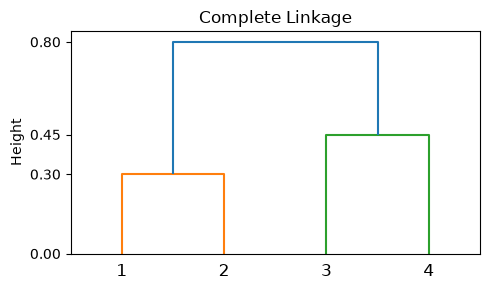

In [10]:
Z_complete = np.array([
    [0, 1, 0.30, 2],
    [2, 3, 0.45, 2],
    [4, 5, 0.80, 4]
])

plot_tree(Z_complete, "Complete Linkage")

**(b)**

Single linkage uses the minimum distance between two clusters.

1. Merge observations 1 and 2 at height 0.3, the smallest distance.
2. The remaining distances are: d({1,2}, {3}) = 0.4, d({1,2}, {4}) = 0.7, d({3}, {4}) = 0.45. Therefore, merge {1,2} and {3} at height 0.4.
3. Merge {1,2,3} and {4} at height min(0.7, 0.8, 0.45) = 0.45.

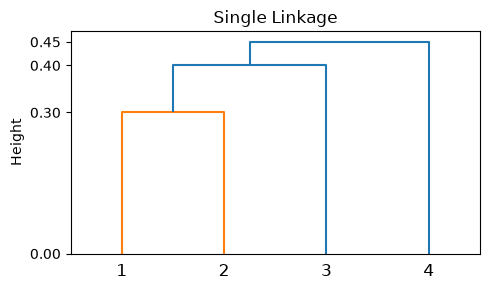

In [11]:
Z_single = np.array([
    [0, 1, 0.30, 2],
    [4, 2, 0.40, 3],
    [5, 3, 0.45, 4]
])

plot_tree(Z_single, "Single Linkage")

**(c)**

Cutting the complete-linkage dendrogram into two clusters gives {1,2} and {3,4}.

**(d)** 

Cutting the single-linkage dendrogram into two clusters gives {1,2,3} and {4}.

**(e)** 

Swap leaves 1 and 2 in the complete-linkage dendrogram.

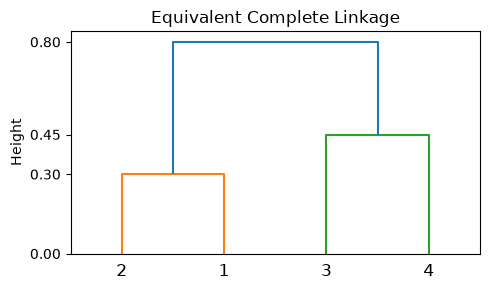

In [12]:
Z_equivalent = Z_complete.copy()
Z_equivalent[0, :2] = Z_equivalent[0, [1, 0]]

plot_tree(Z_equivalent, "Equivalent Complete Linkage")